In [13]:
# import libraries

import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split #this is a func for the splitting of the dataset but the ratio is not fixed, we can set it as we want
from sklearn.preprocessing import StandardScaler # this is a func that puts all the data values onto a comparable scale ,(Std =1 , mean=0)
from sklearn.svm import SVC #this is the SVM implementation in sklearn, we program the svm to be used as classification and for the mac marginal band but the kernel can be changed to linear, polynomial, rbf, sigmoid, etc. easily with the help of this function
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score #these are the metrics that we will use to evaluate the performance of the model



In [ ]:
# LOAD THE DATASET -- dataset contains 569 samples 

data = load_breast_cancer() #load the dataset into a variable called data

#seperate the dataset into features and target variable
X = data.data #features are the independent variables that we will use to predict the target variable
y = data.target #target variable is the dependent variable we want to predict



In [8]:
#SPLIT THE DATASET INTO TRAINING AND TESTING SETS

X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.2, #80% of the data is used for training and 20% for testing.
    random_state =42, #makes the split reproducible
    stratify=y #preserves approximately the same proportion of each class in both sets.
    )



In [9]:
#SCALE THE FEATURES

scale = StandardScaler()

X_train = scale.fit_transform(X_train) #learns the scaling values from training data and applies them.
X_test = scale.transform(X_test)#applies those same learned values to testing data.



In [16]:
#Train the SVM model using 4 kernels

kernels = ['linear', 'poly','rbf','sigmoid']
results = []

for kernel in kernels:
    model = SVC(kernel=kernel) #On each iteration, kernel takes a different value
    model.fit(X_train,y_train) #The model learns the decision boundary from the training inputs and their known labels.
    
    y_pred = model.predict(X_test) #The model predicts the labels for the testing inputs.
    results.append({
    'kernel' : kernel,
    'Accuracy' : accuracy_score(y_test,y_pred),
    'Precision' : precision_score(y_test,y_pred),
    "Recall" : recall_score(y_test,y_pred),
    "F1 Score" : f1_score(y_test,y_pred)
    })

In [17]:
#DISPLAY AND PLOT THE RESULTS AND TABLE

results_df = pd.DataFrame(results)
print(results_df.round(4)) #rounding off to 4 decimal places for better readability

    kernel  Accuracy  Precision  Recall  F1 Score
0   linear    0.9737     0.9859  0.9722    0.9790
1     poly    0.9123     0.8780  1.0000    0.9351
2      rbf    0.9825     0.9861  0.9861    0.9861
3  sigmoid    0.9298     0.9571  0.9306    0.9437


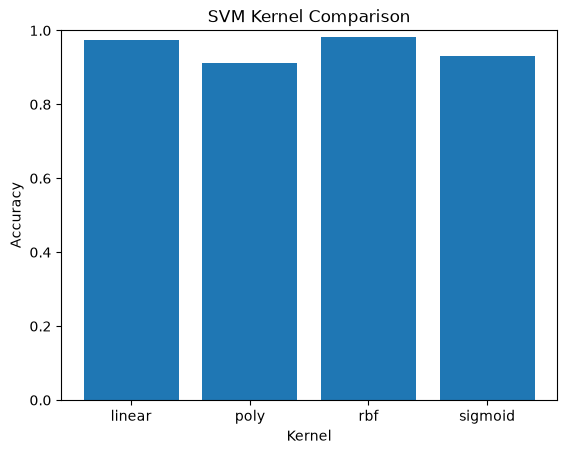

In [18]:
#Plotting the results

plt.title('SVM Kernel Comparison')
plt.xlabel('Kernel')
plt.ylabel('Accuracy')
plt.ylim(0,1)
plt.bar(results_df['kernel'],results_df['Accuracy'])
plt.show()